<a href="https://colab.research.google.com/github/Romanana281/ml-test-task/blob/main/ml_test_mokhnev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Тестовое задание: ML-разработчик
**Мохнев Роман**

Датасет: MonoHime/ru_sentiment_dataset (≈211 тыс. русскоязычных текстов, 3 класса тональности).
Среда: Google Colab, GPU Tesla T4.

## Краткие результаты
**Часть 1. EDA и тематическое моделирование**
- Найдены и устранены проблемы данных: дубликаты, противоречивые метки (3 090 текстов),
  утечка между train и test (1 617 текстов), мусорные тексты. Test оставлен без изменений.
- BERTopic выделил 13 тем, соответствующих источникам датасета (медицина, отели, рестораны,
  авто, новости, политика, соцсети). Распределение тональности сильно зависит от темы —
  метка neutral размечена в источниках неоднородно.

**Часть 2. Классификатор тональности** (метрика — macro-F1, test)

| Модель | macro-F1 | CPU, текстов/с | GPU, текстов/с |
|---|---|---|---|
| TF-IDF + LogReg (бейзлайн) | 0.753 | 4 287 | — |
| rubert-tiny2 (fine-tuning) | **0.784** | 45 | 669 |

**Часть 3** (факультативная) не выполнялась; варианты ускорения инференса описаны в разделе 2.4.

In [ ]:
!pip install -q datasets

In [ ]:
import pandas as pd
import torch
from datasets import load_dataset

DATASET_NAME = "MonoHime/ru_sentiment_dataset"
LABEL_NAMES = {0: "neutral", 1: "positive", 2: "negative"}  # из карточки датасета
JUNK_COLUMNS = ["Unnamed: 0"]  # старый индекс из CSV, смысла не несёт


def load_splits(name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Скачивает датасет с HuggingFace и возвращает train и validation как DataFrame."""
    raw = load_dataset(name)
    return raw["train"].to_pandas(), raw["validation"].to_pandas()


def prepare(df: pd.DataFrame) -> pd.DataFrame:
    """Убирает мусорные колонки и добавляет читаемое имя класса. Исходный df не меняется."""
    return (
        df.drop(columns=JUNK_COLUMNS, errors="ignore")
          .assign(label_name=lambda d: d["sentiment"].map(LABEL_NAMES))
    )


train_raw, valid_raw = load_splits(DATASET_NAME)
train_df, test_df = prepare(train_raw), prepare(valid_raw)

print("GPU доступен:", torch.cuda.is_available())
print("train:", train_df.shape, "| test:", test_df.shape)
train_df.head()

README.md:   0%|          | 0.00/1.65k [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B /  276MB            

train.csv: downloading bytes:           |  0.00B            

valid.csv: reconstructing file:   0%|          |  0.00B / 32.0MB            

valid.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/189891 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21098 [00:00<?, ? examples/s]

GPU доступен: True
train: (189891, 3) | test: (21098, 3)


,text,sentiment,label_name
0,".с.,и спросил его: о Посланник Аллаха!Ты пори...",1,positive
1,Роднее всех родных Попала я в ГКБ №8 еще в дек...,1,positive
2,Непорядочное отношение к своим работникам Рабо...,2,negative
3,"). Отсутствуют нормативы, Госты и прочее, что ...",1,positive
4,У меня машина в руках 5 лет и это п...,1,positive


# Часть 1. Разведочный анализ данных (EDA)
Цель: понять структуру и качество данных до построения моделей —
баланс классов, длины текстов, дубликаты, шум в разметке, характерную лексику.
Выводы EDA используются при выборе метрики, параметров модели и предобработки.

In [ ]:
RANDOM_STATE = 42  # фиксируем случайность, чтобы результаты воспроизводились


def describe_quality(df: pd.DataFrame, name: str) -> None:
    """Печатает базовые проверки качества: пропуски, пустые тексты, дубликаты."""
    empty_texts = df["text"].str.strip().eq("").sum()
    duplicated_texts = df["text"].duplicated().sum()
    print(f"[{name}] строк: {len(df)}")
    print(f"  пропуски по колонкам: {df.isna().sum().to_dict()}")
    print(f"  пустых текстов: {empty_texts}")
    print(f"  повторов текста: {duplicated_texts}")


def count_conflicting_labels(df: pd.DataFrame) -> int:
    """Сколько текстов встречается несколько раз с РАЗНЫМИ метками (признак шума в разметке)."""
    labels_per_text = df.groupby("text")["sentiment"].nunique()
    return int((labels_per_text > 1).sum())


def count_leakage(train: pd.DataFrame, test: pd.DataFrame) -> int:
    """Сколько уникальных текстов есть одновременно в train и в test (утечка данных)."""
    return len(set(train["text"]) & set(test["text"]))


describe_quality(train_df, "train")
describe_quality(test_df, "test")
print("\nТекстов с противоречивыми метками в train:", count_conflicting_labels(train_df))
print("Текстов, попавших и в train, и в test (утечка):", count_leakage(train_df, test_df))

[train] строк: 189891
  пропуски по колонкам: {'text': 0, 'sentiment': 0, 'label_name': 0}
  пустых текстов: 0
  повторов текста: 8788
[test] строк: 21098
  пропуски по колонкам: {'text': 0, 'sentiment': 0, 'label_name': 0}
  пустых текстов: 0
  повторов текста: 137

Текстов с противоречивыми метками в train: 3090
Текстов, попавших и в train, и в test (утечка): 1617


            количество  доля, %
label_name                     
positive         90766     47.8
negative         49798     26.2
neutral          49327     26.0


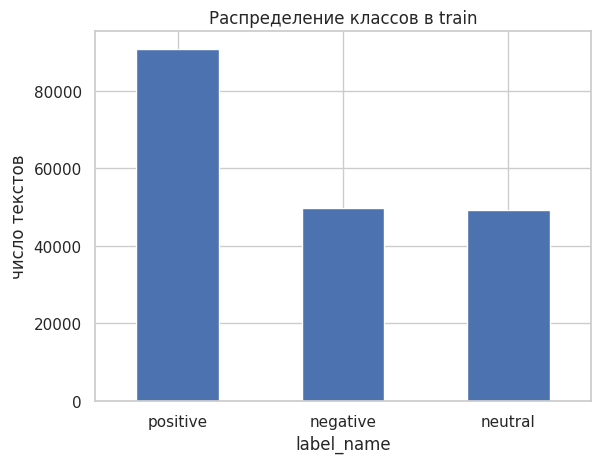

            количество  доля, %
label_name                     
positive         10026     47.5
neutral           5560     26.4
negative          5512     26.1


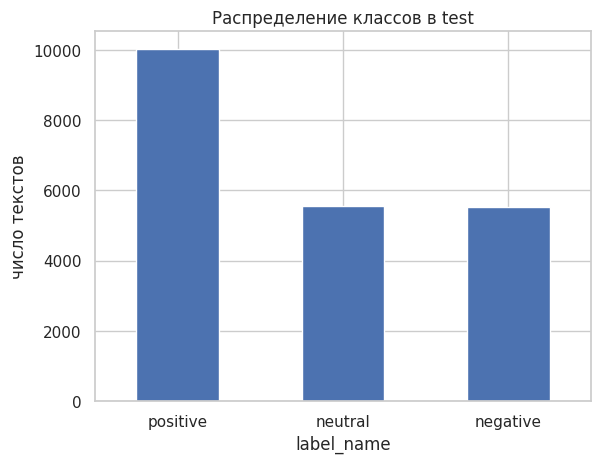

In [ ]:
import matplotlib.pyplot as plt  # библиотека для графиков
import seaborn as sns            # надстройка над matplotlib, графики красивее и проще

sns.set_theme(style="whitegrid")


def show_class_balance(df: pd.DataFrame, title: str) -> None:
    """Печатает таблицу и рисует столбчатую диаграмму распределения классов."""
    counts = df["label_name"].value_counts()
    shares = (counts / counts.sum() * 100).round(1)
    print(pd.DataFrame({"количество": counts, "доля, %": shares}))
    counts.plot(kind="bar", title=title, rot=0)
    plt.ylabel("число текстов")
    plt.show()


show_class_balance(train_df, "Распределение классов в train")
show_class_balance(test_df, "Распределение классов в test")

Статистика длины в словах (train):
count    189891.0
mean        120.3
std         257.4
min           1.0
50%          76.0
90%         232.0
95%         332.0
99%         738.0
max       48146.0
Name: n_words, dtype: float64

Медианная длина по классам:
label_name
negative    77.0
neutral     84.0
positive    73.0
Name: n_words, dtype: float64


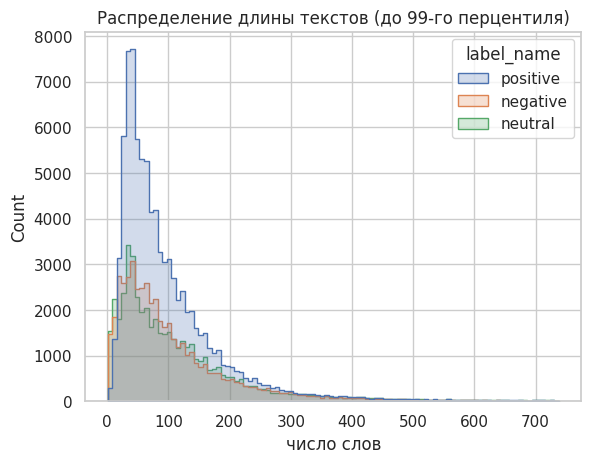

In [ ]:
PERCENTILES = [0.5, 0.9, 0.95, 0.99]


def add_length_features(df: pd.DataFrame) -> pd.DataFrame:
    """Возвращает копию df с колонками длины текста в символах и в словах."""
    return df.assign(
        n_chars=df["text"].str.len(),
        n_words=df["text"].str.split().str.len(),
    )


train_df = add_length_features(train_df)
test_df = add_length_features(test_df)

print("Статистика длины в словах (train):")
print(train_df["n_words"].describe(percentiles=PERCENTILES).round(1))
print("\nМедианная длина по классам:")
print(train_df.groupby("label_name")["n_words"].median())

# Отсекаем 1% самых длинных текстов только для графика, иначе выбросы сожмут всё в одну полоску
max_words_shown = train_df["n_words"].quantile(0.99)
sns.histplot(
    data=train_df[train_df["n_words"] <= max_words_shown],
    x="n_words", hue="label_name", bins=100, element="step",
)
plt.title("Распределение длины текстов (до 99-го перцентиля)")
plt.xlabel("число слов")
plt.show()

In [ ]:
SAMPLES_PER_CLASS = 3
PREVIEW_CHARS = 300


def show_examples(df: pd.DataFrame, n: int) -> None:
    """Печатает n случайных текстов каждого класса (обрезанных для читаемости)."""
    for label, group in df.groupby("label_name"):
        print(f"\n===== {label} =====")
        for text in group["text"].sample(n, random_state=RANDOM_STATE):
            print("•", text[:PREVIEW_CHARS].replace("\n", " "))


show_examples(train_df, SAMPLES_PER_CLASS)

print("\n===== Самые короткие тексты =====")
print(train_df.nsmallest(10, "n_chars")[["text", "label_name"]].to_string())


===== negative =====
• Ужинали с друзьями вечером 28 марта .  Даже не думали , что в центре еще остались такие приятные ресторанчики как Палати !  Спасибо , очень вкусно по демакратичным ценам , приятный и вежливый персонал !!! Все быстро , четко ))) Обязательно вернемся !  
• Нет гарантии на оправу 07.01.2014 заказала очки дочери (стоимость по чеку 3950,00). 24.03.2014 - сломалась оправа (крепление оправы с душкой). Обратилась в магазин - они предложили мне поменять оправу (стоимость около 4000,00). Сказали, что гарантия на оправу не распространяется. Осталась не довольн
• Долой главного врача Даллакяна Савонина Валентина Михайловна. Обращаюсь с жалобой на главного врача поликлиники №6. Хамское отношение к персоналу и посетителям поликлиники. Экономия на всем-бахилы не выдаются, а прячутся у охранника на случай проверки. Очень холодно-отопление по вечерам отключают, в

===== neutral =====
• Приобрел автомобиль (автобус 17 мест) в 2007 г. (ПТС 2006 г.) у фирмы производителя Самотлор-Н

In [ ]:
import re
from collections import Counter

import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

RUSSIAN_STOPWORDS = set(stopwords.words("russian"))
WORD_PATTERN = re.compile(r"[а-яё]+")  # только русские слова
MIN_WORD_LEN = 3
TOP_N_WORDS = 20
EDA_SAMPLE_PER_CLASS = 20_000


def tokenize(text: str) -> list[str]:
    """Разбивает текст на русские слова в нижнем регистре, без стоп-слов и коротких слов."""
    return [
        word for word in WORD_PATTERN.findall(text.lower())
        if len(word) >= MIN_WORD_LEN and word not in RUSSIAN_STOPWORDS
    ]


def top_words(texts: pd.Series, n: int) -> list[str]:
    """n самых частых слов в наборе текстов."""
    counter = Counter()
    for text in texts:
        counter.update(tokenize(text))
    return [word for word, _ in counter.most_common(n)]


def top_words_by_class(df: pd.DataFrame) -> pd.DataFrame:
    """Таблица: колонка = класс, строки = самые частые слова этого класса."""
    result = {}
    for label, group in df.groupby("label_name"):
        sample = group["text"].sample(min(len(group), EDA_SAMPLE_PER_CLASS), random_state=RANDOM_STATE)
        result[label] = top_words(sample, TOP_N_WORDS)
    return pd.DataFrame(result)


top_words_by_class(train_df)

,negative,neutral,positive
0,это,это,очень
1,очень,очень,это
2,врач,отель,спасибо
3,просто,года,отель
4,день,номер,просто
5,нам,номера,персонал
6,время,отеля,благодарность
7,врача,просто,всем
8,деньги,отеле,года
9,вообще,номере,время


мало букв (мусор)         удалено: 14
противоречивые метки      удалено: 7783
повторы                   удалено: 4093
утечка (есть в test)      удалено: 1304

Осталось 176697 из 189891 строк
            количество  доля, %
label_name                     
positive         83860     47.5
negative         48687     27.6
neutral          44150     25.0


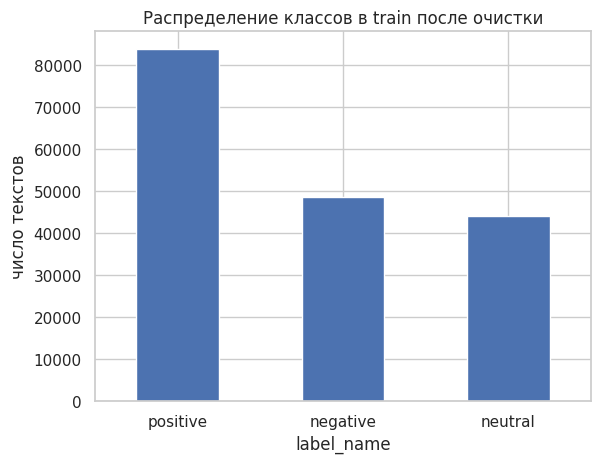

In [ ]:
MIN_LETTERS = 5  # текст, где меньше 5 букв, не несёт тональности: "!", "))", ":-("
LETTER_PATTERN = r"[a-zA-Zа-яА-ЯёЁ]"


def has_enough_letters(texts: pd.Series, min_letters: int) -> pd.Series:
    """Для каждого текста True, если в нём не меньше min_letters букв."""
    return texts.str.count(LETTER_PATTERN) >= min_letters


def conflicting_texts(df: pd.DataFrame) -> set[str]:
    """Тексты, которые встречаются с разными метками."""
    labels_per_text = df.groupby("text")["sentiment"].nunique()
    return set(labels_per_text[labels_per_text > 1].index)


def clean_train(train: pd.DataFrame, test: pd.DataFrame) -> pd.DataFrame:
    """Последовательно применяет шаги очистки к train и печатает, сколько строк удалил каждый шаг."""
    test_texts = set(test["text"])
    steps = [
        ("мало букв (мусор)",     lambda d: d[has_enough_letters(d["text"], MIN_LETTERS)]),
        ("противоречивые метки",  lambda d: d[~d["text"].isin(conflicting_texts(d))]),
        ("повторы",               lambda d: d.drop_duplicates(subset="text")),
        ("утечка (есть в test)",  lambda d: d[~d["text"].isin(test_texts)]),
    ]

    result = train
    for step_name, step in steps:
        rows_before = len(result)
        result = step(result)
        print(f"{step_name:<25} удалено: {rows_before - len(result)}")

    print(f"\nОсталось {len(result)} из {len(train)} строк")
    return result.reset_index(drop=True)


train_clean = clean_train(train_df, test_df)
show_class_balance(train_clean, "Распределение классов в train после очистки")

### Выводы EDA
1. **Пропусков нет**, но есть мусорные тексты без смысла ("!", "))", ":-(") — удаляем из train тексты, где меньше 5 букв.
2. **Шум в разметке**: 3 090 текстов встречаются с разными метками, при ручном просмотре видны явно
   ошибочные метки (благодарность ресторану помечена как negative). Противоречивые тексты удаляем;
   потолок качества любой модели на этих данных ограничен качеством разметки.
3. **Дубликаты и утечка**: 8 788 повторов в train и 1 617 текстов, попавших одновременно в train и test.
   Повторы и пересечение удаляем из train, test оставляем без изменений, чтобы оценка была честной.
4. **Дисбаланс классов** (positive ≈ 48%, negative и neutral ≈ 26%), одинаковый в train и test →
   accuracy неинформативна, основная метрика — macro-F1; при разбиении train/val используем стратификацию.
5. **Длины**: медиана 76 слов, 95% текстов короче 332 слов, максимум ~48 тыс. слов (выбросы).
   Длина почти не зависит от класса. Для трансформера ограничиваем вход 256 токенами.
6. **Связь класса с источником**: частые слова отражают тематику (отели, врачи, новости Казахстана),
   а не тональность; нейтральный класс в основном про отели и новости. Есть риск, что модель выучит
   источник текста вместо тональности — это проверим при анализе ошибок.
7. **Очистка**: После очистки в train осталось 176 697 текстов (93%), распределение классов сохранилось

### Часть 1.2. Тематическое моделирование

**Выбор алгоритма.** Рассмотренные варианты:

| Алгоритм | Как работает | Минусы для наших данных |
|---|---|---|
| LDA | вероятностная модель на «мешке слов» | не учитывает смысл и синонимы; для русского нужна лемматизация; плохо работает на коротких текстах; число тем задаётся заранее |
| NMF | матричное разложение TF-IDF | те же ограничения «мешка слов» |
| Top2Vec | эмбеддинги + кластеризация | меньше инструментов настройки и визуализации |
| **BERTopic** | эмбеддинги трансформера → UMAP → HDBSCAN → c-TF-IDF | дольше считается, требует GPU для эмбеддингов |

Выбран **BERTopic**: он работает со смыслом текста (синонимы и разные формы слов попадают в одну тему
без лемматизации), сам определяет число тем, выделяет нетипичные тексты в отдельную группу выбросов
и имеет встроенные визуализации. Мультиязычная модель эмбеддингов поддерживает русский.

Для скорости модель строится на случайной подвыборке 30 000 текстов — этого достаточно, чтобы
выявить основные темы корпуса.

In [ ]:
!pip install -q bertopic sentence-transformers

In [ ]:
from sentence_transformers import SentenceTransformer

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EMBEDDING_MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
TOPIC_SAMPLE_SIZE = 30_000
EMBEDDING_BATCH_SIZE = 128


def sample_texts(df: pd.DataFrame, n: int) -> pd.DataFrame:
    """Случайная подвыборка n строк (воспроизводимая за счёт RANDOM_STATE)."""
    return df.sample(n=min(n, len(df)), random_state=RANDOM_STATE).reset_index(drop=True)


topic_sample = sample_texts(train_clean, TOPIC_SAMPLE_SIZE)
docs = topic_sample["text"].tolist()

embedder = SentenceTransformer(EMBEDDING_MODEL_NAME, device=DEVICE)
embeddings = embedder.encode(docs, batch_size=EMBEDDING_BATCH_SIZE, show_progress_bar=True)
print("Размер матрицы эмбеддингов:", embeddings.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/235 [00:00<?, ?it/s]

Размер матрицы эмбеддингов: (30000, 384)


In [ ]:
from bertopic import BERTopic
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP

MIN_TOPIC_SIZE = 150         # тема должна объединять хотя бы 150 текстов из 30 000, иначе это шум
UMAP_DIMENSIONS = 5
UMAP_NEIGHBORS = 15
MIN_WORD_DOC_FREQ = 5        # слово должно встретиться хотя бы в 5 текстах, чтобы попасть в описание темы
RUSSIAN_WORD_TOKEN = r"(?u)\b[а-яёa-z]{3,}\b"  # слова от 3 букв, без чисел
EXTRA_STOPWORDS = {"это", "очень", "просто", "всё", "также", "которые", "вообще", "хотя", "туда", "нам", "всем"}
TOPIC_STOPWORDS = sorted(RUSSIAN_STOPWORDS | EXTRA_STOPWORDS)


def build_topic_model(embedding_model: SentenceTransformer) -> BERTopic:
    """Собирает BERTopic из настроенных компонентов: сжатие → кластеризация → описание тем."""
    umap_model = UMAP(
        n_neighbors=UMAP_NEIGHBORS, n_components=UMAP_DIMENSIONS,
        min_dist=0.0, metric="cosine", random_state=RANDOM_STATE,
    )
    hdbscan_model = HDBSCAN(
        min_cluster_size=MIN_TOPIC_SIZE, metric="euclidean",
        cluster_selection_method="eom", prediction_data=True,
    )
    vectorizer_model = CountVectorizer(
        stop_words=TOPIC_STOPWORDS, token_pattern=RUSSIAN_WORD_TOKEN,
        min_df=MIN_WORD_DOC_FREQ, ngram_range=(1, 2),
    )
    return BERTopic(
        embedding_model=embedding_model,
        umap_model=umap_model,
        hdbscan_model=hdbscan_model,
        vectorizer_model=vectorizer_model,
        verbose=True,
    )


topic_model = build_topic_model(embedder)
topics, _ = topic_model.fit_transform(docs, embeddings)

topic_info = topic_model.get_topic_info()
print("Найдено тем (без выбросов):", len(topic_info) - 1)
print("Доля выбросов (тема -1):", round((pd.Series(topics) == -1).mean() * 100, 1), "%")
topic_info.head(20)

2026-10-14 21:05:29,616 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-10-14 21:06:03,074 - BERTopic - Dimensionality - Completed ✓
2026-10-14 21:06:03,076 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-10-14 21:06:10,524 - BERTopic - Cluster - Completed ✓
2026-10-14 21:06:10,534 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-10-14 21:06:17,422 - BERTopic - Representation - Completed ✓


Найдено тем (без выбросов): 13
Доля выбросов (тема -1): 9.0 %


,Topic,Count,Name,Representation,Representative_Docs
0,-1,2713,-1_тенге_время_года_лет,"[тенге, время, года, лет, почему, деньги, очки...",[Купила Матиз 2 месяца назад. Думала между 211...
1,0,8996,0_спасибо_врач_благодарность_врачи,"[спасибо, врач, благодарность, врачи, отношени...",[Хочу поблагодарить врача и сотрудников 21 отд...
2,1,6541,1_отель_номер_номера_отеля,"[отель, номер, номера, отеля, отеле, номере, п...","[Расположение отеля очень удачное, какой бы ва..."
3,2,4867,2_ресторан_меню_обслуживание_кухня,"[ресторан, меню, обслуживание, кухня, вкусно, ...",[Посетили с подружками ресторан в середине янв...
4,3,1268,3_зуб_зубы_спасибо_врач,"[зуб, зубы, спасибо, врач, зубов, клинике, леч...",[Специалист в своем деле Очень боюсь стоматоло...
5,4,981,4_машина_автомобиль_авто_машину,"[машина, автомобиль, авто, машину, машины, год...","[Да простят меня Уважаемые Читатели,Нивоводы,н..."
6,5,961,5_года_тенге_казахстана_году,"[года, тенге, казахстана, году, млрд, казахста...","[Астана, 28 декабря, Дом Мажилиса Сегодня в..."
7,6,895,6_отель_номера_номер_отеле,"[отель, номера, номер, отеле, персонал, отеля,...","[Хороший отель в историческом центре Москвы, р..."
8,7,800,7_пафос_тебе_твой_твоя,"[пафос, тебе, твой, твоя, успешного, помог, по...",[Тебе послышалось. Менты орали моритури те сал...
9,8,790,8_россии_народ_власти_путин,"[россии, народ, власти, путин, контексте, прот...",[ользователь сослался на вашу запись в записи...


### Часть 1.3. Визуализация

In [ ]:
TOP_TOPICS_TO_SHOW = 12
WORDS_PER_TOPIC = 8

topic_model.visualize_barchart(top_n_topics=TOP_TOPICS_TO_SHOW, n_words=WORDS_PER_TOPIC)

In [ ]:
topic_model.visualize_topics()

In [ ]:
topic_model.visualize_hierarchy()

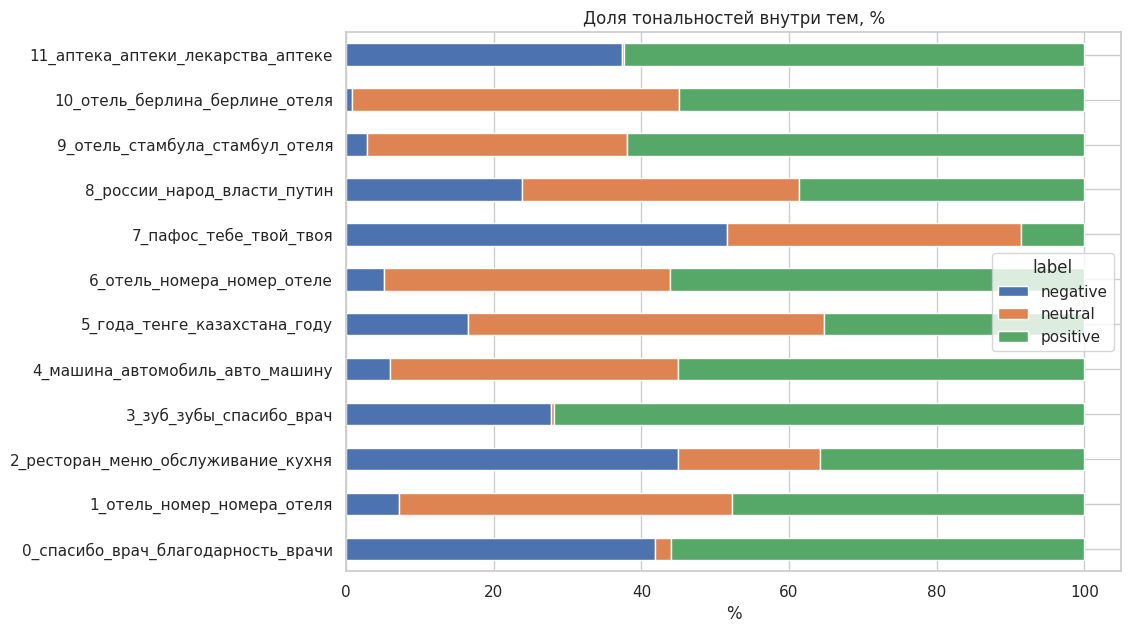

label,negative,neutral,positive
0_спасибо_врач_благодарность_врачи,41.9,2.1,56.0
1_отель_номер_номера_отеля,7.2,45.1,47.7
2_ресторан_меню_обслуживание_кухня,44.9,19.3,35.8
3_зуб_зубы_спасибо_врач,27.7,0.4,71.9
4_машина_автомобиль_авто_машину,5.9,39.0,55.0
5_года_тенге_казахстана_году,16.5,48.2,35.3
6_отель_номера_номер_отеле,5.1,38.8,56.1
7_пафос_тебе_твой_твоя,51.6,39.8,8.6
8_россии_народ_власти_путин,23.8,37.5,38.7
9_отель_стамбула_стамбул_отеля,2.8,35.3,61.9


In [ ]:
def sentiment_share_by_topic(topic_ids: list[int], labels: pd.Series, top_n: int) -> pd.DataFrame:
    """Доли классов тональности (в %) внутри крупнейших тем, без темы выбросов."""
    frame = pd.DataFrame({"topic": topic_ids, "label": labels.to_numpy()})
    frame = frame[frame["topic"] != -1]
    largest_topics = frame["topic"].value_counts().head(top_n).index
    shares = pd.crosstab(frame["topic"], frame["label"], normalize="index") * 100
    return shares.loc[largest_topics].round(1)


sentiment_by_topic = sentiment_share_by_topic(topics, topic_sample["label_name"], TOP_TOPICS_TO_SHOW)
sentiment_by_topic.index = [topic_model.get_topic_info(t)["Name"].iloc[0] for t in sentiment_by_topic.index]
sentiment_by_topic.plot(kind="barh", stacked=True, figsize=(10, 7), title="Доля тональностей внутри тем, %")
plt.xlabel("%")
plt.show()
sentiment_by_topic

### Выводы по тематическому моделированию
1. BERTopic выделил 13 тем, 9% текстов отнесены к выбросам (тема -1) — это тексты без выраженной тематики.
2. Темы соответствуют источникам, из которых собран датасет: медицина (благодарности врачам,
   стоматология, аптеки), отели (5 тем, разделённых по городам), рестораны, автомобили,
   новости Казахстана, политика, грубые комментарии из соцсетей.
3. Карта тем и иерархия показывают три крупных кластера: отели; медицина; новости/политика/комментарии.
   Темы отелей сливаются на малом расстоянии — фактически это одна тема с подтемами по городам.
4. Распределение тональности сильно зависит от темы: в медицинских темах почти нет нейтральных
   текстов (0.4–2%), в отелях почти нет негативных (1–7%), в грубых комментариях почти нет позитивных.
   Вероятно, источники размечались по разным схемам (в части источников разметка фактически бинарная),
   и метка neutral имеет разный смысл в разных доменах.
5. Следствие для классификатора: есть риск, что модель будет опираться на тему текста, а не на тональность.
   Это нужно учитывать при анализе ошибок (качество по доменам).

### Часть 1.4. Варианты улучшения тематического моделирования

1. **Лемматизация для описания тем.** Сейчас в ключевых словах повторяются формы одного слова
   (отель / отеля / отеле). Приведение слов к начальной форме (pymorphy3, Natasha) на этапе
   CountVectorizer сделает описания тем чище и информативнее. Эмбеддинги при этом считаются по исходному тексту.
2. **Расширение списка стоп-слов** доменно-зависимыми словами без смысловой нагрузки
   (местоимения «тебе», «твой», слова «года», «время»), чтобы они не попадали в описания тем.
3. **Более сильная модель эмбеддингов для русского языка** (например, multilingual-e5, sbert_large_nlu_ru,
   USER от deepvk). Текущая MiniLM учитывает только первые 128 токенов — длинные тексты обрезаются.
   Альтернатива — разбивать длинные тексты на фрагменты и усреднять их эмбеддинги.
4. **Подбор гиперпараметров** (min_cluster_size, n_neighbors, n_components) по метрикам качества тем:
   когерентности (c_v, NPMI) и разнообразию тем, а не только «на глаз».
5. **Объединение близких тем** (topic_model.merge_topics / reduce_topics): например, 5 тем про отели
   в одну тему с подтемами — по иерархии видно, что они почти не различаются.
6. **Работа с выбросами**: reduce_outliers — переназначить тексты темы -1 ближайшим темам,
   если нужна полная разметка корпуса.
7. **Более понятные названия тем**: представления KeyBERTInspired или MMR (убирает дублирующие слова),
   либо генерация названий тем с помощью LLM.
8. **Обучение на всём корпусе** вместо подвыборки 30 000 текстов — позволит найти редкие темы.
9. **Предобработка**: удаление обрезанных фрагментов текста и мусора; разбиение очень длинных
   текстов на абзацы, поскольку один длинный текст может содержать несколько тем.
10. **Проверка устойчивости**: несколько запусков с разными random_state — устойчивые темы
    должны воспроизводиться.

# Часть 2. Классификатор тональности

### 2.1 Разбиение данных
- **test** — официальный validation-split датасета (21 098 текстов), не изменяется и используется
  только для финальной оценки.
- **train / val** — очищенный train делится в пропорции 90/10 со стратификацией по классу
  (доли классов в обеих частях одинаковые).
- val используется для подбора гиперпараметров и выбора лучшей эпохи, test — один раз в конце.
  Так оценка на test остаётся честной: решения не подгоняются под тестовые данные.

In [ ]:
from sklearn.model_selection import train_test_split

VAL_SIZE = 0.1  # 10% train → val: ~17 тыс. текстов, достаточно для надёжной оценки


def split_train_val(df: pd.DataFrame, val_size: float) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Делит df на train и val со стратификацией по классу."""
    train_part, val_part = train_test_split(
        df, test_size=val_size, stratify=df["sentiment"], random_state=RANDOM_STATE,
    )
    return train_part.reset_index(drop=True), val_part.reset_index(drop=True)


def print_split_summary(parts: dict[str, pd.DataFrame]) -> None:
    """Размер и доли классов каждой части — проверяем, что стратификация сработала."""
    for name, part in parts.items():
        shares = part["label_name"].value_counts(normalize=True).mul(100).round(1).to_dict()
        print(f"{name:<6} {len(part):>7} строк | доли классов, %: {shares}")


train_part, val_part = split_train_val(train_clean, VAL_SIZE)
print_split_summary({"train": train_part, "val": val_part, "test": test_df})

train   159027 строк | доли классов, %: {'positive': 47.5, 'negative': 27.6, 'neutral': 25.0}
val      17670 строк | доли классов, %: {'positive': 47.5, 'negative': 27.6, 'neutral': 25.0}
test     21098 строк | доли классов, %: {'positive': 47.5, 'neutral': 26.4, 'negative': 26.1}


### 2.2 Метрика, функция потерь, бейзлайн
**Метрика — macro-F1.** Классы несбалансированы (positive ≈ 48%), поэтому accuracy завышает качество
модели, хорошо распознающей только частый класс. Macro-F1 считает F1 по каждому классу и усредняет
без весов — ошибки в малых классах (negative, neutral) штрафуются так же, как в большом.
Дополнительно приводим accuracy, precision/recall по классам и матрицу ошибок.

**Функция потерь — кросс-энтропия** (log loss) — стандарт для многоклассовой классификации:
сильнее штрафует уверенные ошибки и даёт откалиброванные вероятности. Для учёта дисбаланса
используются веса классов (class_weight="balanced"), обратно пропорциональные частоте класса.

**Бейзлайн — TF-IDF + логистическая регрессия.** Быстро обучается на CPU, хорошо работает на текстах
и задаёт точку отсчёта для оценки того, сколько качества добавляет нейросеть.
Параметры TF-IDF: униграммы и биграммы (учитываем «не понравилось», «не рекомендую»),
min_df=3 (убираем опечатки и редкий шум), sublinear_tf (логарифм частоты — длинные тексты
не доминируют). Коэффициент регуляризации C подбирается по macro-F1 на val.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

TFIDF_PARAMS = dict(
    ngram_range=(1, 2),     # слова и пары слов: "не понравилось" — это одна единица смысла
    min_df=3,               # слово должно встретиться хотя бы в 3 текстах — отсекаем опечатки
    max_df=0.9,             # слова, которые есть в >90% текстов, бесполезны
    max_features=300_000,   # ограничиваем словарь, чтобы влезло в память
    sublinear_tf=True,      # 1 + log(частота): слово 100 раз ≠ в 100 раз важнее
)

vectorizer = TfidfVectorizer(**TFIDF_PARAMS)
X_train = vectorizer.fit_transform(train_part["text"])
X_val = vectorizer.transform(val_part["text"])
X_test = vectorizer.transform(test_df["text"])
y_train, y_val, y_test = (part["sentiment"].to_numpy() for part in (train_part, val_part, test_df))

print("Размер словаря:", len(vectorizer.vocabulary_))
print("Матрица train:", X_train.shape)

Размер словаря: 300000
Матрица train: (159027, 300000)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

C_CANDIDATES = [0.5, 1.0, 2.0, 4.0]
MAX_ITER = 1000  # максимум шагов оптимизации; с запасом, чтобы обучение успело сойтись


def train_logreg(X, y, c: float) -> LogisticRegression:
    """Обучает логистическую регрессию с весами классов против дисбаланса."""
    model = LogisticRegression(C=c, max_iter=MAX_ITER, class_weight="balanced")
    return model.fit(X, y)


models_by_c = {}
val_f1_by_c = {}
for c in C_CANDIDATES:
    models_by_c[c] = train_logreg(X_train, y_train, c)
    val_f1_by_c[c] = f1_score(y_val, models_by_c[c].predict(X_val), average="macro")
    print(f"C={c:<4} macro-F1 на val: {val_f1_by_c[c]:.4f}")

best_c = max(val_f1_by_c, key=val_f1_by_c.get)
baseline = models_by_c[best_c]
print(f"\nЛучшее C = {best_c}")

C=0.5  macro-F1 на val: 0.7716
C=1.0  macro-F1 на val: 0.7763
C=2.0  macro-F1 на val: 0.7780
C=4.0  macro-F1 на val: 0.7759

Лучшее C = 2.0


=== TF-IDF + LogReg (test) ===
accuracy: 0.7559 | macro-F1: 0.7532

              precision    recall  f1-score   support

     neutral      0.605     0.762     0.675      5560
    positive      0.856     0.723     0.784     10026
    negative      0.793     0.810     0.801      5512

    accuracy                          0.756     21098
   macro avg      0.751     0.765     0.753     21098
weighted avg      0.773     0.756     0.760     21098



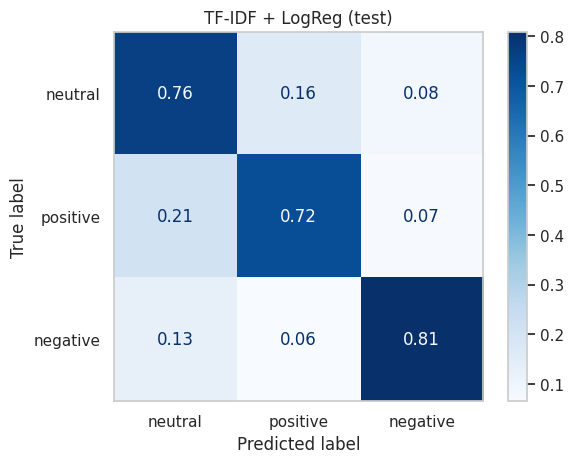

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report

LABEL_ORDER = [0, 1, 2]
TARGET_NAMES = [LABEL_NAMES[label] for label in LABEL_ORDER]


def evaluate(y_true, y_pred, title: str) -> dict[str, float]:
    """Печатает метрики и матрицу ошибок; возвращает accuracy и macro-F1 для сводной таблицы."""
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
    }
    print(f"=== {title} ===")
    print(f"accuracy: {metrics['accuracy']:.4f} | macro-F1: {metrics['macro_f1']:.4f}\n")
    print(classification_report(y_true, y_pred, labels=LABEL_ORDER, target_names=TARGET_NAMES, digits=3))

    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=LABEL_ORDER, display_labels=TARGET_NAMES,
        normalize="true", values_format=".2f", cmap="Blues",
    )
    plt.title(title)
    plt.grid(False)
    plt.show()
    return metrics


baseline_metrics = evaluate(y_test, baseline.predict(X_test), "TF-IDF + LogReg (test)")

In [ ]:
import time

SPEED_SAMPLE_SIZE = 2_000   # на скольких текстах замеряем скорость
SPEED_RUNS = 3              # повторяем замер и берём лучший — убираем случайные задержки

speed_texts = test_df["text"].sample(SPEED_SAMPLE_SIZE, random_state=RANDOM_STATE).tolist()


def measure_throughput(predict_fn, texts: list[str], n_runs: int = SPEED_RUNS) -> float:
    """Пропускная способность: сколько текстов в секунду обрабатывает predict_fn (лучший из n_runs замеров)."""
    best_seconds = float("inf")
    for _ in range(n_runs):
        start = time.perf_counter()
        predict_fn(texts)
        best_seconds = min(best_seconds, time.perf_counter() - start)
    return len(texts) / best_seconds


def predict_baseline(texts: list[str]):
    """Полный путь инференса бейзлайна: текст → TF-IDF → класс."""
    return baseline.predict(vectorizer.transform(texts))


baseline_speed = measure_throughput(predict_baseline, speed_texts)
print(f"TF-IDF + LogReg, CPU: {baseline_speed:.0f} текстов/сек")

TF-IDF + LogReg, CPU: 4287 текстов/сек


### Результаты бейзлайна
- Лучший коэффициент регуляризации C = 2 (macro-F1 на val = 0.778).
- На test: **macro-F1 = 0.753**, accuracy = 0.756, скорость инференса на CPU ≈ 4 300 текстов/с.
- Лучше всего распознаётся negative (F1 = 0.80), хуже всего neutral (F1 = 0.675, precision 0.605).
- Основная ошибка — путаница positive ↔ neutral (21% positive предсказаны как neutral);
  positive и negative путаются редко (6–7%). Это согласуется с выводом EDA о разном смысле
  метки neutral в разных источниках.
- Ограничение подхода: «мешок слов» не учитывает порядок слов и контекст
  («не очень хорошо», сарказм, смешанные отзывы) — это мотивирует переход к трансформеру.

### 2.3 Дообучение трансформера rubert-tiny2

**Выбор модели.** `cointegrated/rubert-tiny2` — компактный BERT для русского языка (29 млн параметров).
Альтернативы: rubert-base (~180 млн, качество выше на 1–3 п.п., но в 6–10 раз медленнее),
xlm-roberta-base (~280 млн, мультиязычная, тяжёлая). Поскольку в задании важна скорость инференса,
в том числе на CPU, выбрана быстрая модель, учитывающая контекст и порядок слов — то, чего нет у TF-IDF.

**Гиперпараметры** (типичные значения для дообучения BERT-моделей):
- max_length = 256 токенов — по статистике длины в токенах (см. ниже): полностью покрывает большинство, медиана 107 токенов, 84% текстов полностью помещаются в 256 токенов
  текстов; тональность длинных отзывов, как правило, видна в начале;
- learning rate = 5e-5 — верхняя граница стандартного диапазона 2e-5…5e-5, маленькие модели
  дообучаются при чуть большем шаге;
- batch size = 64, 3 эпохи — данных много, 2–4 эпох обычно достаточно; лучшая эпоха выбирается
  по macro-F1 на val (защита от переобучения);
- warmup 6% шагов — плавный разгон шага обучения, чтобы не «сломать» предобученные веса в начале;
- weight decay = 0.01 — регуляризация;
- fp16 — вычисления в половинной точности, ускорение на GPU примерно в 2 раза.

**Функция потерь** — взвешенная кросс-энтропия с весами классов, как в бейзлайне
(сравнение моделей корректно). **Метрика выбора лучшей эпохи** — macro-F1 на val.

In [ ]:
from transformers import AutoTokenizer

MODEL_NAME = "cointegrated/rubert-tiny2"
MAX_LENGTH = 256
TOKEN_STATS_SAMPLE = 5_000

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

sample_for_tokens = train_part["text"].sample(TOKEN_STATS_SAMPLE, random_state=RANDOM_STATE).tolist()
token_lengths = pd.Series([len(ids) for ids in tokenizer(sample_for_tokens)["input_ids"]])

print(token_lengths.describe(percentiles=PERCENTILES).round(0))
print(f"\nДоля текстов, целиком влезающих в {MAX_LENGTH} токенов: {(token_lengths <= MAX_LENGTH).mean():.1%}")

config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (3024 > 2048). Running this sequence through the model will result in indexing errors


count    5000.0
mean      170.0
std       266.0
min         4.0
50%       107.0
90%       336.0
95%       490.0
99%      1025.0
max      6771.0
dtype: float64

Доля текстов, целиком влезающих в 256 токенов: 84.2%


In [ ]:
from datasets import Dataset
from transformers import DataCollatorWithPadding


def to_hf_dataset(df: pd.DataFrame) -> Dataset:
    """pandas → формат HuggingFace: колонки text и label."""
    frame = df[["text", "sentiment"]].rename(columns={"sentiment": "label"})
    return Dataset.from_pandas(frame, preserve_index=False)


def tokenize_batch(batch: dict) -> dict:
    """Превращает тексты в токены, обрезая слишком длинные до MAX_LENGTH."""
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)


encoded = {
    name: to_hf_dataset(df).map(tokenize_batch, batched=True, remove_columns=["text"])
    for name, df in {"train": train_part, "val": val_part, "test": test_df}.items()
}
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
encoded

Map:   0%|          | 0/159027 [00:00<?, ? examples/s]

Map:   0%|          | 0/17670 [00:00<?, ? examples/s]

Map:   0%|          | 0/21098 [00:00<?, ? examples/s]

{'train': Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
     num_rows: 159027
 }),
 'val': Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
     num_rows: 17670
 }),
 'test': Dataset({
     features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
     num_rows: 21098
 })}

In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments

class_weights = torch.tensor(
    compute_class_weight("balanced", classes=np.array(LABEL_ORDER), y=y_train),
    dtype=torch.float,
)
print("Веса классов (neutral, positive, negative):", class_weights.numpy().round(2))


class WeightedLossTrainer(Trainer):
    """Trainer с взвешенной кросс-энтропией: ошибки на редких классах штрафуются сильнее."""

    def __init__(self, *args, class_weights: torch.Tensor, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss_fn = torch.nn.CrossEntropyLoss(weight=self.class_weights.to(outputs.logits.device))
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred) -> dict[str, float]:
    """Метрики на val после каждой эпохи; по macro_f1 выбирается лучшая эпоха."""
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "macro_f1": f1_score(labels, predictions, average="macro"),
        "accuracy": accuracy_score(labels, predictions),
    }


model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(LABEL_ORDER),
    id2label=LABEL_NAMES,
    label2id={name: label for label, name in LABEL_NAMES.items()},
)

Веса классов (neutral, positive, negative): [1.33 0.7  1.21]


model.safetensors: reconstructing file:   0%|          |  0.00B /  118MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
import math

OUTPUT_DIR = "rubert_tiny2_sentiment"
TRAIN_BATCH_SIZE = 64
NUM_EPOCHS = 3
WARMUP_SHARE = 0.06  # 6% шагов обучения — плавный разгон learning rate


def count_warmup_steps(n_train: int, batch_size: int, epochs: int, warmup_share: float) -> int:
    """Число шагов разгона: доля от общего числа шагов обучения (шаг = одна пачка)."""
    total_steps = math.ceil(n_train / batch_size) * epochs
    return int(total_steps * warmup_share)


warmup_steps = count_warmup_steps(len(encoded["train"]), TRAIN_BATCH_SIZE, NUM_EPOCHS, WARMUP_SHARE)
print("Шагов разгона:", warmup_steps)

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    learning_rate=5e-5,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=128,
    num_train_epochs=NUM_EPOCHS,
    weight_decay=0.01,
    warmup_steps=warmup_steps,
    fp16=torch.cuda.is_available(),
    eval_strategy="epoch",          # после каждой эпохи — оценка на val
    save_strategy="epoch",          # и сохранение чекпоинта
    load_best_model_at_end=True,    # в конце берём лучшую эпоху, а не последнюю
    metric_for_best_model="macro_f1",
    save_total_limit=2,
    logging_steps=200,
    report_to="none",
    seed=RANDOM_STATE,
)

trainer = WeightedLossTrainer(
    model=model,
    args=training_args,
    train_dataset=encoded["train"],
    eval_dataset=encoded["val"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    class_weights=class_weights,
)

trainer.train()

Шагов разгона: 447


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,0.461419,0.447754,0.782891,0.784437
2,0.389117,0.434163,0.807461,0.813469
3,0.327547,0.446381,0.807027,0.813639


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=7455, training_loss=0.42699699760043003, metrics={'train_runtime': 1254.5469, 'train_samples_per_second': 380.282, 'train_steps_per_second': 5.942, 'total_flos': 1759276384436736.0, 'train_loss': 0.42699699760043003, 'epoch': 3.0})

=== rubert-tiny2 (test) ===
accuracy: 0.7877 | macro-F1: 0.7844

              precision    recall  f1-score   support

     neutral      0.646     0.755     0.697      5560
    positive      0.859     0.771     0.812     10026
    negative      0.838     0.851     0.844      5512

    accuracy                          0.788     21098
   macro avg      0.781     0.792     0.784     21098
weighted avg      0.797     0.788     0.790     21098



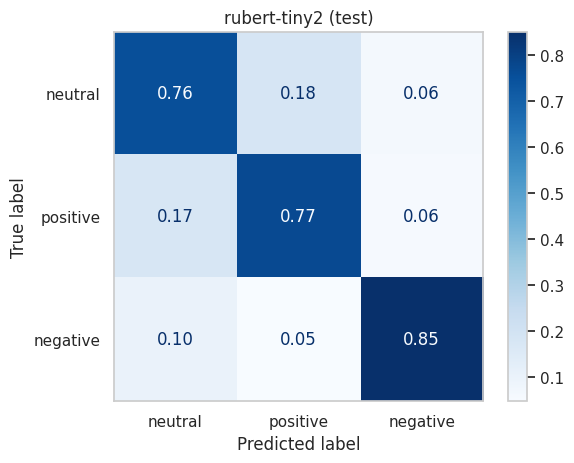

In [ ]:
test_logits = trainer.predict(encoded["test"]).predictions
bert_metrics = evaluate(y_test, np.argmax(test_logits, axis=-1), "rubert-tiny2 (test)")

In [ ]:
from google.colab import drive

drive.mount("/content/drive")
SAVED_MODEL_DIR = "/content/drive/MyDrive/ml_test/rubert_tiny2_best"
trainer.save_model(SAVED_MODEL_DIR)  # сохраняет и веса лучшей эпохи, и токенизатор
print("Модель сохранена в", SAVED_MODEL_DIR)

Mounted at /content/drive


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Модель сохранена в /content/drive/MyDrive/ml_test/rubert_tiny2_best


In [ ]:
import copy

INFERENCE_BATCH_SIZE = 64
LATENCY_SAMPLE_SIZE = 200   # для задержки хватит 200 текстов: каждый обрабатывается отдельно
CPU_RUNS = 1                # на CPU медленно, достаточно одного прогона


def make_bert_predictor(model, device: str, batch_size: int):
    """Возвращает функцию texts -> классы: токенизация пачками и прогон модели на device."""
    model = model.to(device).eval()

    @torch.inference_mode()
    def predict(texts: list[str]) -> np.ndarray:
        predictions = []
        for start in range(0, len(texts), batch_size):
            batch = tokenizer(
                texts[start:start + batch_size], truncation=True, max_length=MAX_LENGTH,
                padding=True, return_tensors="pt",
            ).to(device)
            predictions.append(model(**batch).logits.argmax(dim=-1).cpu())
        return torch.cat(predictions).numpy()

    return predict


def measure_latency_ms(predict_fn, texts: list[str]) -> float:
    """Средняя задержка на один текст (мс), когда тексты приходят по одному — как в онлайн-сервисе."""
    start = time.perf_counter()
    for text in texts:
        predict_fn([text])
    return (time.perf_counter() - start) / len(texts) * 1000


latency_texts = speed_texts[:LATENCY_SAMPLE_SIZE]

# GPU: модель уже на видеокарте
predict_gpu = make_bert_predictor(trainer.model, "cuda", INFERENCE_BATCH_SIZE)
predict_gpu(speed_texts[:INFERENCE_BATCH_SIZE])  # прогрев: первый запуск на GPU всегда медленнее
bert_gpu_speed = measure_throughput(predict_gpu, speed_texts)
bert_gpu_latency = measure_latency_ms(predict_gpu, latency_texts)

# CPU: отдельная копия модели, чтобы не трогать GPU-версию
cpu_model = copy.deepcopy(trainer.model).to("cpu")
predict_cpu = make_bert_predictor(cpu_model, "cpu", INFERENCE_BATCH_SIZE)
bert_cpu_speed = measure_throughput(predict_cpu, speed_texts, n_runs=CPU_RUNS)
bert_cpu_latency = measure_latency_ms(predict_cpu, latency_texts)

baseline_latency = measure_latency_ms(predict_baseline, latency_texts)

print(f"rubert-tiny2 GPU: {bert_gpu_speed:.0f} текстов/с, {bert_gpu_latency:.1f} мс/текст")
print(f"rubert-tiny2 CPU: {bert_cpu_speed:.0f} текстов/с, {bert_cpu_latency:.1f} мс/текст")
print(f"TF-IDF + LogReg CPU: {baseline_speed:.0f} текстов/с, {baseline_latency:.1f} мс/текст")

rubert-tiny2 GPU: 669 текстов/с, 5.7 мс/текст
rubert-tiny2 CPU: 45 текстов/с, 12.7 мс/текст
TF-IDF + LogReg CPU: 4287 текстов/с, 3.9 мс/текст


In [ ]:
def summary_row(name: str, metrics: dict, cpu_speed: float, gpu_speed: float, cpu_latency: float) -> dict:
    """Одна строка сводной таблицы: качество + скорость."""
    return {
        "модель": name,
        "macro-F1": metrics["macro_f1"],
        "accuracy": metrics["accuracy"],
        "CPU, текстов/с": cpu_speed,
        "GPU, текстов/с": gpu_speed,
        "CPU, мс/текст": cpu_latency,
    }


summary = pd.DataFrame([
    summary_row("TF-IDF + LogReg", baseline_metrics, baseline_speed, np.nan, baseline_latency),
    summary_row("rubert-tiny2", bert_metrics, bert_cpu_speed, bert_gpu_speed, bert_cpu_latency),
]).set_index("модель").round(3)
summary

,macro-F1,accuracy,"CPU, текстов/с","GPU, текстов/с","CPU, мс/текст"
модель,,,,,
TF-IDF + LogReg,0.753,0.756,4287.382,NaN,3.876
rubert-tiny2,0.784,0.788,44.956,668.683,12.742


### Итоги части 2
- Обучение: лучшая эпоха — 2-я (macro-F1 на val = 0.807). На 3-й эпохе training loss продолжал
  снижаться, а validation loss вырос — начало переобучения; благодаря load_best_model_at_end
  итоговая модель взята с 2-й эпохи.
- На test rubert-tiny2 достигает **macro-F1 = 0.784** против 0.753 у бейзлайна (+3.1 п.п.),
  улучшение по всем классам; сильнее всего вырос F1 класса negative (0.80 → 0.84) — модель учитывает
  контекст и отрицания.
- Самый сложный класс — neutral (F1 = 0.70): основная путаница positive ↔ neutral (17–18%),
  что объясняется неоднородной разметкой этого класса в разных источниках (см. EDA и темы).
- Скорость (Colab: GPU Tesla T4, CPU 2 ядра):
  rubert-tiny2 на GPU — 669 текстов/с при пакетной обработке, 5.7 мс на одиночный текст;
  на CPU — 45 текстов/с пачками, 12.7 мс на одиночный текст; бейзлайн на CPU — 4 287 текстов/с, 3.9 мс.
  GPU быстрее CPU примерно в 15 раз; на CPU трансформер почти в 100 раз медленнее бейзлайна —
  это цена прироста качества и мотивация для оптимизации инференса (часть 3).
- На CPU пакетная обработка оказалась медленнее поштучной: при динамическом дополнении все тексты
  пачки дополняются до длины самого длинного, и вычисления на «пустых» токенах доминируют.
  Сортировка текстов по длине перед формированием пачек устранила бы этот эффект.

### 2.4 Варианты улучшения

### Качество
1. **Работа с шумом разметки**: поиск ошибочных меток (confident learning, библиотека cleanlab),
   переразметка спорных примеров; label smoothing в функции потерь — снижает уверенность модели
   на шумных метках.
2. **Согласование класса neutral между источниками**: учитывать домен текста (отели, медицина,
   новости) как дополнительный признак или обучать модель с многозадачной «головой»
   (тональность + домен), анализировать качество по доменам.
3. **Более крупная модель**: rubert-base, ruRoBERTa-large, xlm-roberta-large — обычно +1–3 п.п.
   ценой скорости; ансамбль нескольких моделей.
4. **Длинные тексты**: max_length 512 или стратегия «начало + конец» текста (тональность отзыва
   часто в первой и последней фразах); сейчас 16% текстов обрезаются.
5. **Подбор гиперпараметров** (learning rate, число эпох, batch size, layer-wise LR decay)
   с помощью Optuna; ранняя остановка по val.
6. **Порог для класса neutral**: подбор порогов вероятностей на val вместо argmax, калибровка
   вероятностей.
7. **Дополнительные данные**: RuSentiment, RuReviews и др.; аугментации (обратный перевод, перефразирование).

### Скорость
1. **Экспорт в ONNX Runtime** — оптимизированный движок инференса, объединение операций графа.
2. **INT8-квантизация** весов для CPU — модель меньше в ~4 раза и быстрее при минимальной потере качества.
3. **fp16 / bf16 на GPU**, TensorRT — ускорение инференса на видеокарте в 2+ раза.
4. **Дистилляция** в ещё меньшую модель или удаление части слоёв (pruning).
5. **Сортировка текстов по длине** при пакетной обработке — меньше «пустых» токенов-дополнений.
6. **Уменьшение max_length** до 128 — ускорение почти в 2 раза; компромисс с качеством нужно замерить.